## Imports

In [1]:
import torch # Main PyTorch library for tensor operations and deep learning
from torch import nn # Neural network module for building models (Used for creating layers, loss functions, etc.)
from torch.optim import Adam # Optimizer for training the model (Used for updating model weights during training)
import torchvision.transforms as transforms # Image transformation module for preprocessing images (Used for resizing, normalizing, etc.)
from torchvision import models # Pre-trained models module for transfer learning (Used for loading pre-trained models like ResNet, VGG, etc.)
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import LabelEncoder # Label encoder for converting string labels to numerical format (Used for encoding class labels)
import matplotlib.pyplot as plt # Plotting library for visualizing data and results (Used for plotting images, loss curves, etc.)
from PIL import Image # Python Imaging Library for image processing (Used for opening and manipulating images)
import pandas as pd # Data manipulation library for handling tabular data (Used for reading the CSV files)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Set device to GPU if available, otherwise use CPU (Used for running computations on the appropriate hardware)
print(f"Using device: {device}") # Print the device being used for computations (Helps in debugging and ensuring correct device usage)

Using device: cuda


## Reading Data Paths

In [2]:
train_df = pd.read_csv("../data/bean-leaf-lesions-classification/train.csv") # Load training data from CSV file (Contains image paths and labels for training)
val_df = pd.read_csv("../data/bean-leaf-lesions-classification/val.csv") # Load validation data from CSV file (Contains image paths and labels for validation)

data_df = pd.concat([train_df, val_df], ignore_index=True) # Combine training and validation data into a single DataFrame (Used for creating a unified dataset for training and validation)

data_df["image:FILE"] = "../data/bean-leaf-lesions-classification/" + data_df["image:FILE"] # Prepend the base path to image file names (Ensures correct file paths for loading images)

print("Data shape is:", data_df.shape) # Print the shape of the combined DataFrame (Helps in understanding the size of the dataset)
print()
data_df.head() # Display the first few rows of the combined DataFrame (Helps in verifying the data structure and contents)

Data shape is: (1167, 2)



,image:FILE,category
0,../data/bean-leaf-lesions-classification/train...,0
1,../data/bean-leaf-lesions-classification/train...,0
2,../data/bean-leaf-lesions-classification/train...,0
3,../data/bean-leaf-lesions-classification/train...,0
4,../data/bean-leaf-lesions-classification/train...,0


## Data Inspection

In [3]:
print("Classes are: ", data_df["category"].unique()) # Print the unique class labels in the dataset
print()
print("Classes distribution are: ", data_df["category"].value_counts()) # Print the distribution of class labels in the dataset (Helps in understanding class imbalance)

Classes are:  [0 1 2]

Classes distribution are:  category
2    393
1    389
0    385
Name: count, dtype: int64


## Data Split

- Training: 70%
- Testing: 30%

In [4]:
train = data_df.sample(frac= 0.7, random_state=42) # Randomly sample 70% of the data for training
test = data_df.drop(train.index) # Use the remaining 30% of the data for testing

print("Train shape is:", train.shape) # Print the shape of the training DataFrame (Helps in understanding the size of the training dataset)
print("Test shape is:", test.shape) # Print the shape of the testing DataFrame (Helps in understanding the size of the testing dataset)

Train shape is: (817, 2)
Test shape is: (350, 2)


## Preprocessing Objects

In [5]:
label_encoder = LabelEncoder()
label_encoder.fit(train["category"]) # fit() only learns the mapping from labels to numbers, it doesn't convert anything yet

transform = transforms.Compose([
    transforms.Resize((128, 128)), # Resize images to 128x128 pixels
    transforms.ToTensor(), # Convert images to PyTorch tensors
    transforms.ConvertImageDtype(torch.float), # Convert image data type to float
]) # Transform all images to a consistent format for model input (preprocess all images to same properties)

## Custom Dataset Class

In [6]:
class CustomImageDataset(Dataset):
    def __init__(self, dataframe, transform=None): # Initialize the custom dataset with a DataFrame and optional transformations
        self.dataframe = dataframe # Store the DataFrame containing image paths and labels
        self.transform = transform # Store the transformations to be applied to the images
        self.labels = label_encoder.transform(dataframe["category"]) # Encode the labels with the fitted label encoder (the result is a NumPy array on the CPU, which is why the loops move labels to the device)

    def __len__(self):
        return self.dataframe.shape[0] # Return the number of rows in the DataFrame (Each row corresponds to one sample)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx, 0] # Get the image path from the DataFrame
        label = self.labels[idx] # Get the corresponding label from the encoded labels
        image = Image.open(img_path).convert("RGB") # Open the image and convert it to RGB format

        if self.transform:
            image = self.transform(image).to(device) # Apply transformations to the image if specified

        return image, label # Return the transformed image and its label

## Create Dataset Objects

In [7]:
train_dataset = CustomImageDataset(dataframe=train, transform=transform)
test_dataset = CustomImageDataset(dataframe=test, transform=transform)

## Visualize Images

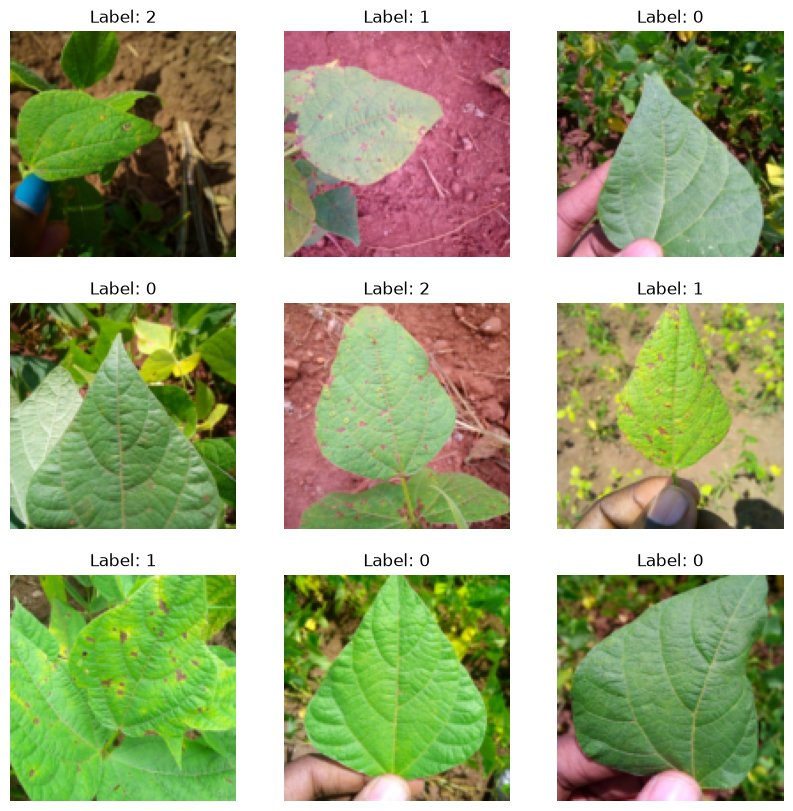

In [8]:
n_rows = 3
n_cols = 3

f, axarr = plt.subplots(n_rows, n_cols, figsize=(10, 10)) # Create a grid of subplots for displaying images
for row in range(n_rows):
    for col in range(n_cols):
        idx = row * n_cols + col # Calculate the index of the image to display
        image, label = train_dataset[idx] # Get the image and label from the training dataset
        axarr[row, col].imshow(image.permute(1, 2, 0).cpu().numpy()) # Display the image (Permute dimensions for correct display)
        axarr[row, col].set_title(f"Label: {label_encoder.inverse_transform([label])[0]}") # Set the title of the subplot to the corresponding label
        axarr[row, col].axis('off') # Turn off axis for better visualization

# Label 0 : Healthy
# Label 1 : Angular Leaf Spot
# Label 2 : Bean Rust

## Hyperparameters

In [9]:
LR = 1e-3 # Learning rate for the optimizer (Controls the step size during gradient descent) 1e-3 = 0.001
BATCH_SIZE = 4
EPOCHS = 15

## Data Loaders

In [10]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True) # Create a DataLoader for the training dataset (Used for batching and shuffling data during training)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False) # Create a DataLoader for the testing dataset (No shuffling needed for evaluation)

## Model

In [11]:
googlenet_model = models.googlenet(weights='DEFAULT')
for param in googlenet_model.parameters():
  param.requires_grad = True

In [12]:
googlenet_model.fc

Linear(in_features=1024, out_features=1000, bias=True)

In [13]:
num_classes = len(data_df["category"].unique()) # Get the number of unique classes in the dataset (Used for defining the output layer of the model)
googlenet_model.fc = torch.nn.Linear(in_features=googlenet_model.fc.in_features, out_features=num_classes) # Replace the final fully connected layer to match the number of classes (Allows the model to output predictions for the specific dataset)
googlenet_model.to(device)

GoogLeNet(
  (conv1): BasicConv2d(
    (conv): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
  (conv2): BasicConv2d(
    (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (conv3): BasicConv2d(
    (conv): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(192, eps=0.001, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (maxpool2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
  (inception3a): Inception(
    (branch1): BasicConv2d(
      (conv): Conv2d(192, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001,

## Loss and Optimizer

In [14]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Cross Entropy Loss
optimizer = Adam(googlenet_model.parameters(), lr=LR) # Adam optimizer

## Training

In [15]:
total_loss_train_plot = []
total_acc_train_plot = []

for epoch in range(EPOCHS):
    googlenet_model.train() # Training mode: BatchNorm layers use the statistics of the current batch
    total_loss_train = 0
    total_acc_train = 0

    for (inputs, labels) in train_loader:
        inputs, labels = inputs.to(device), labels.to(device) # Move inputs and labels to the specified device (GPU or CPU)

        optimizer.zero_grad() # Zero the gradients of the optimizer (Prevents accumulation of gradients from previous iterations)

        outputs = googlenet_model(inputs) # Forward pass: compute predicted outputs by passing inputs to the model

        train_loss = criterion(outputs, labels) # Calculate the loss between predicted outputs and true labels
        total_loss_train += train_loss.item() # Accumulate training loss
        train_loss.backward() # Backward pass: compute gradient of the loss with respect to model parameters

        train_acc = (torch.argmax(outputs, dim=1) == labels).sum().item() # Calculate the number of correct predictions in the batch
        total_acc_train += train_acc # Accumulate number of correct predictions

        optimizer.step() # Update model parameters based on computed gradients

    total_loss_train_plot.append(total_loss_train / len(train_loader)) # Store average training loss for the epoch
    total_acc_train_plot.append(total_acc_train / len(train_dataset)) # Store average training accuracy

    print(f"Epoch [{epoch+1}/{EPOCHS}], Train Loss: {total_loss_train / len(train_loader):.4f}, Train Accuracy: {total_acc_train / len(train_dataset):.4f}") # Print epoch number, average loss, and accuracy for the epoch
    print()

Epoch [1/15], Train Loss: 0.8198, Train Accuracy: 0.6267



Epoch [2/15], Train Loss: 0.6756, Train Accuracy: 0.7417



Epoch [3/15], Train Loss: 0.5194, Train Accuracy: 0.7993



Epoch [4/15], Train Loss: 0.5155, Train Accuracy: 0.8188



Epoch [5/15], Train Loss: 0.4313, Train Accuracy: 0.8482



...

Epoch [11/15], Train Loss: 0.2226, Train Accuracy: 0.9327



Epoch [12/15], Train Loss: 0.2079, Train Accuracy: 0.9217



Epoch [13/15], Train Loss: 0.2308, Train Accuracy: 0.9266



Epoch [14/15], Train Loss: 0.1616, Train Accuracy: 0.9449



Epoch [15/15], Train Loss: 0.2245, Train Accuracy: 0.9290



## Testing

In [16]:
googlenet_model.eval() # Evaluation mode: BatchNorm layers use the statistics learned during training

with torch.no_grad(): # Disable gradient calculation for evaluation (Reduces memory usage and speeds up computations)
    total_loss_test = 0
    total_acc_test = 0

    for (inputs, labels) in test_loader:
        inputs, labels = inputs.to(device), labels.to(device) # Move inputs and labels to the specified device (GPU or CPU)

        outputs = googlenet_model(inputs) # Forward pass: compute predicted outputs by passing inputs to the model

        test_loss = criterion(outputs, labels) # Calculate the loss between predicted outputs and true labels
        total_loss_test += test_loss.item() # Accumulate testing loss

        test_acc = (torch.argmax(outputs, dim=1) == labels).sum().item() # Calculate the number of correct predictions in the batch
        total_acc_test += test_acc # Accumulate number of correct predictions

    print(f"Test Loss: {total_loss_test / len(test_loader):.4f}, Test Accuracy: {total_acc_test / len(test_dataset):.4f}") # Print average loss and accuracy for the test dataset

Test Loss: 0.3290, Test Accuracy: 0.8886


## Plotting Training Progress

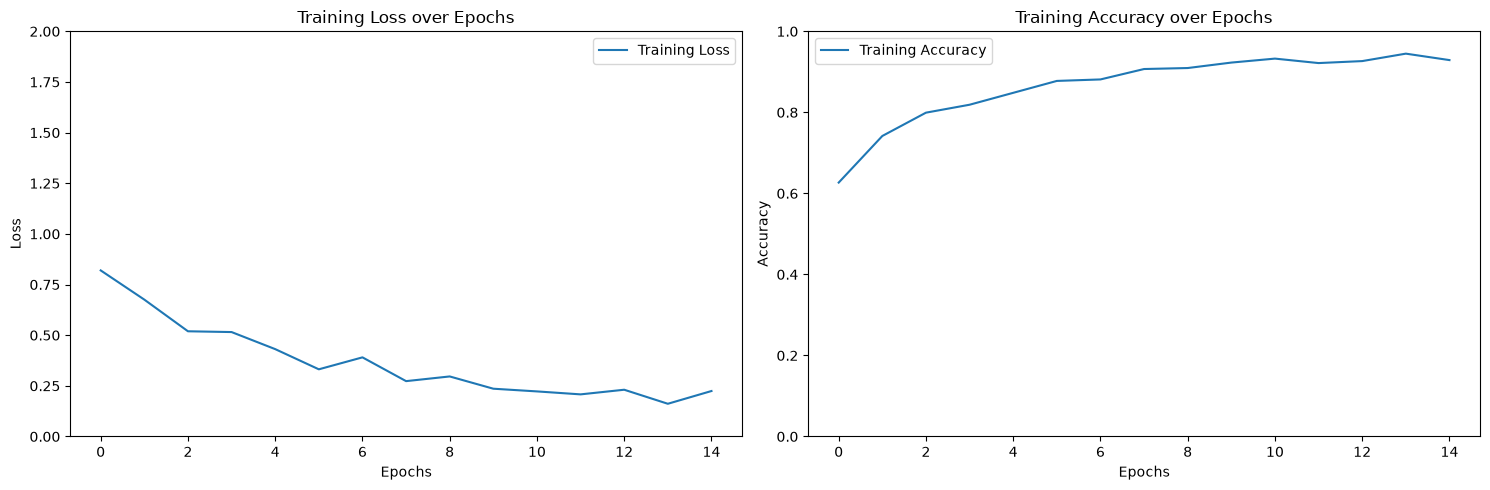

In [17]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].set_title('Training Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].set_ylim([0, 2])
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].set_title('Training Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].set_ylim([0, 1]) # Accuracy is stored as a fraction from 0 to 1
axs[1].legend()

plt.tight_layout()

plt.show()

# 🌱 How This Notebook Works, from Zero (study notes)

> 📝 **Note:** This explanation was **written by Claude (AI)** at my request, so I could understand what happens in this notebook, especially **how the model works** and **what "pretrained" means**. All the **code** is typed by me while following the video.
>
> The numbers come from this notebook's own data and its last run. Training uses randomness, so a new run gives slightly different results.

---

## 0. The big picture

```
📄 train.csv + val.csv  (photo address + class number)
   │  1. merge into one table, add the folder path
   ▼
data_df        1,167 rows  →  split 70 / 30  →  train 817 · test 350
   │  2. Dataset + DataLoader (same idea as Project 02)
   ▼
one batch = 4 photos  →  tensor (4, 3, 128, 128)
   │  3. a model that ALREADY knows how to see (GoogLeNet, pretrained on ImageNet)
   │     with its last layer swapped: 1,000 classes → 3 classes
   ▼
3 scores per photo  →  highest score wins: healthy / angular leaf spot / bean rust
```

---

## 1. The data

Photos of bean leaves, sorted into **3 classes**:

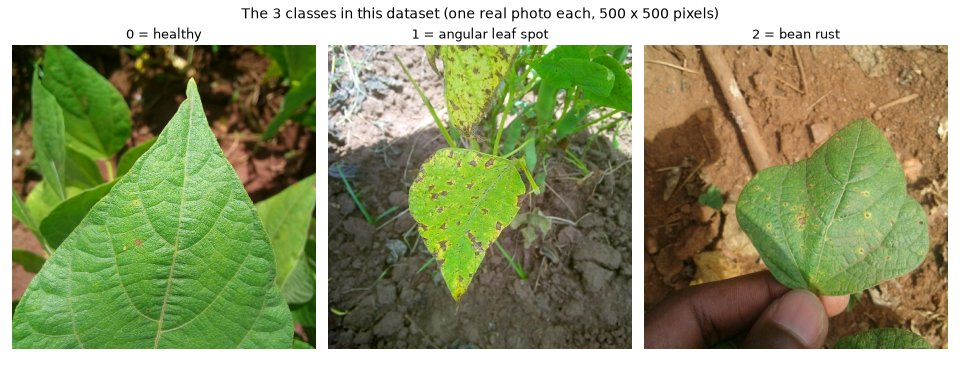

| Number | Class | Photos |
|---|---|---|
| 0 | healthy | 385 |
| 1 | angular leaf spot | 389 |
| 2 | bean rust | 393 |
| | **Total** | **1,167** |

- The CSV files already give each photo a **number** (0, 1, 2), so the label encoder doesn't really have to change anything here. It's kept for good habit.
- `pd.concat` joins `train.csv` and `val.csv` into one table, then we split it ourselves: **817 for training, 350 for testing** (70 / 30, no validation set).

## 2. Preparing the photos (same as Project 02)

- **Dataset**: a warehouse of photo addresses. A photo is opened only when asked for, resized to **128 × 128**, and turned into a tensor `(3, 128, 128)` with numbers from 0.0 to 1.0.
- **DataLoader**: stacks **4** photos at a time → `(4, 3, 128, 128)`.

| Loader | Batches per epoch |
|---|---|
| `train_loader` | **205** (817 = 204 × 4 + 1) |
| `test_loader` | 88 (350 = 87 × 4 + 2) |

Only **817** training photos is very little for a deep model. In Project 02, the CNN learned from **11,291** photos. That's why this project uses a **pretrained** model.

---

## 3. What does "pretrained" mean?

**Pretrained = someone else already trained the model on a huge dataset, and we reuse what it learned.**

> 📸 **Analogy:** teaching a newborn baby to recognise leaf diseases would take forever, because first it has to learn how to *see* at all. Hiring an **experienced photographer** is much faster. They already know edges, colours, textures and shapes. You only need to show them a few examples: *"this is healthy, this is rust, this is leaf spot"*.

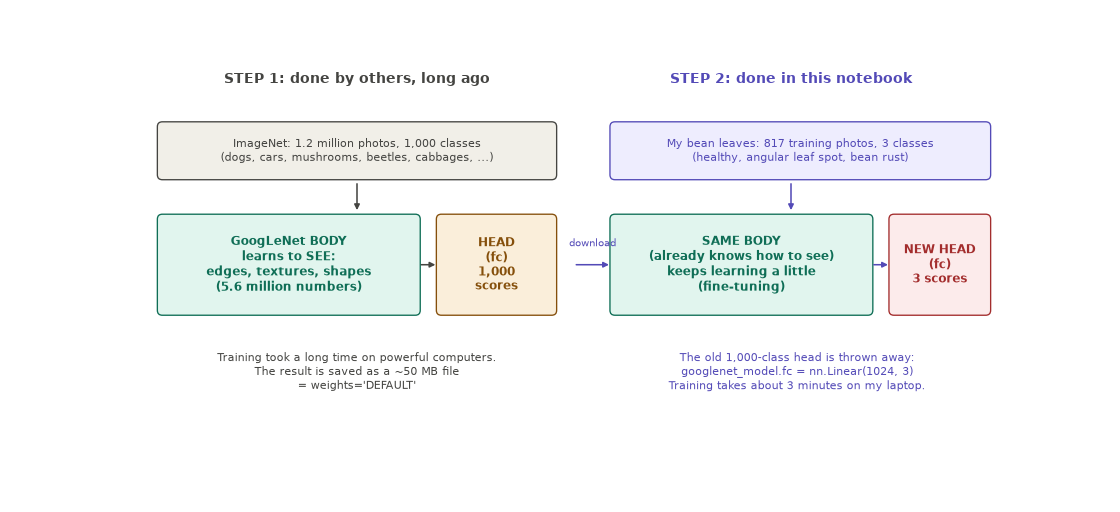

- **ImageNet** is a famous dataset with about **1.2 million photos** in **1,000 classes** (dogs, cars, mushrooms, beetles, cabbages, ...).
- **GoogLeNet** was trained on ImageNet. Its knowledge is saved as a **~50 MB file of numbers** (the weights).
- `models.googlenet(weights='DEFAULT')` **downloads those weights** (the first time only) and builds the model with them. On ImageNet, this model guesses the exact class right about **70%** of the time, out of 1,000 classes.

### Before fine-tuning: what does the original model think of my leaves?

I showed one leaf from each class to the **original** GoogLeNet, before changing anything:

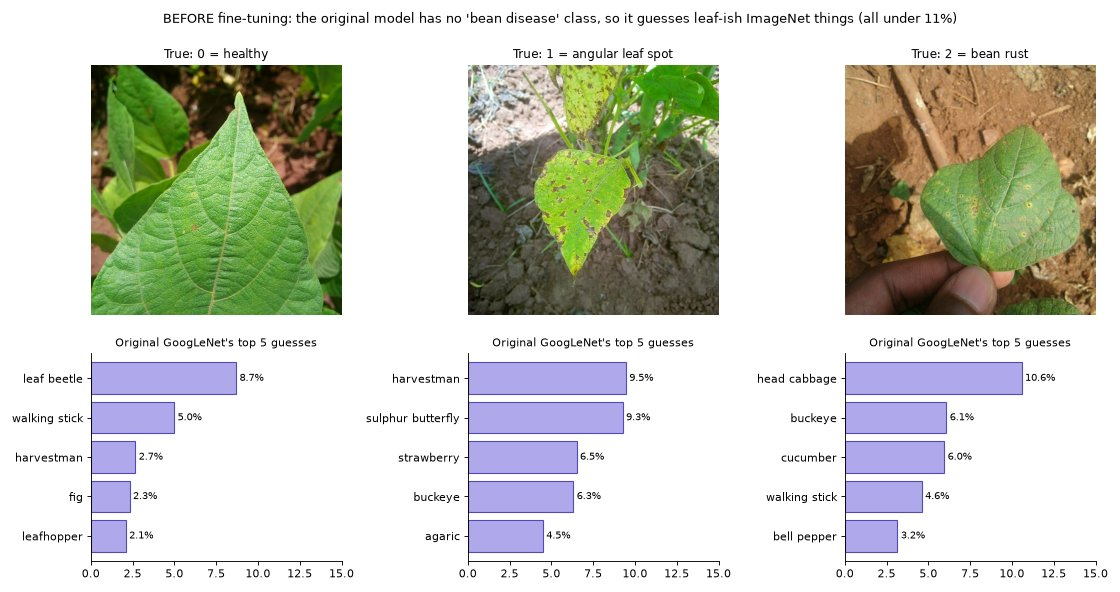

ImageNet has **no** "bean disease" class, so the model picks the closest things it knows: *leaf beetle*, *walking stick*, *head cabbage*... always with low confidence (under 11%).

👉 This shows the key idea: the model **already knows how to look** at leaves (it picks leafy, green, plant-like things), but it **doesn't know our 3 classes**. That's exactly what we teach it.

---

## 4. How GoogLeNet works, step by step

GoogLeNet is a **much bigger CNN** than the one in Project 02, but the idea is the same: **look for patterns, shrink the picture, decide**.

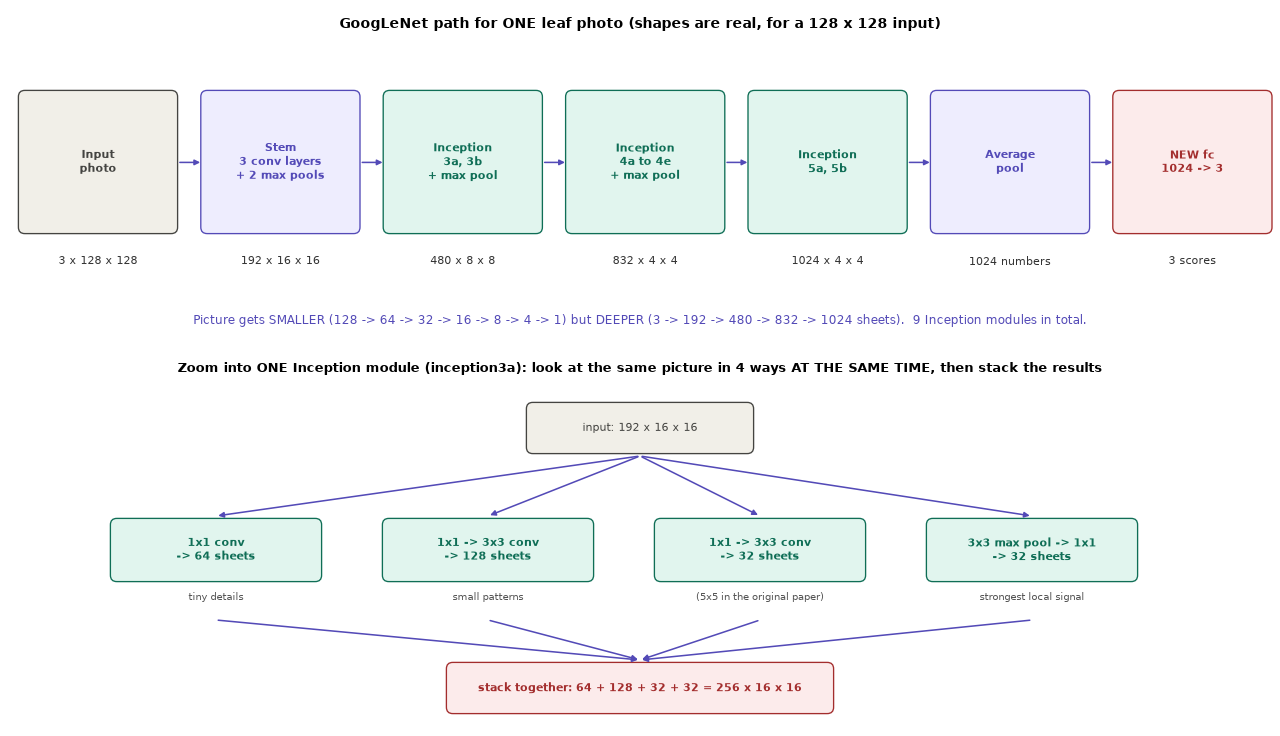

| Step | What happens | Shape for one photo |
|---|---|---|
| Input | my leaf photo | 3 × 128 × 128 |
| **Stem** | 3 conv layers + 2 max pools: find simple patterns (edges, colours), shrink fast | 192 × 16 × 16 |
| **Inception 3a, 3b** + pool | find small patterns (spots, veins) | 480 × 8 × 8 |
| **Inception 4a → 4e** + pool | combine them into bigger patterns (lesion shapes, leaf texture) | 832 × 4 × 4 |
| **Inception 5a, 5b** | the most complex patterns | 1024 × 4 × 4 |
| **Average pool** | average each of the 1,024 sheets into one number | 1,024 numbers |
| **fc** (the head) | turn 1,024 numbers into scores | **3 scores** |

### The special part: the Inception module 🔭
A normal CNN layer looks at a picture with **one** window size. An **Inception module** looks at the same picture in **4 ways at the same time** (a 1×1 branch, a 3×3 branch, a second 3×3 branch that was 5×5 in the original paper, and a max-pooling branch), then **stacks all the results together**. This way it catches both tiny details and slightly larger patterns in one step. GoogLeNet stacks **9** of these modules.

- **1×1 convolution**: it sounds strange, but it's very useful. It mixes the sheets together and **reduces how many there are** before the more expensive 3×3 step. That keeps the model small and fast.
- **BatchNorm**: inside GoogLeNet, every convolution is followed by a **BatchNorm** layer (57 of them). See section 6, because it matters a lot.

### Parameters
| Part | Parameters | Where they come from |
|---|---|---|
| Body (everything except `fc`) | 5,599,904 | **pretrained** on ImageNet |
| New head `fc` | 3,075 (1,024 × 3 + 3) | **random**, learned from my leaves |
| **Total** | **5,602,979** | |

The original head had **1,025,000** parameters (1,024 × 1,000 + 1,000), and we threw it away.

---

## 5. The head swap and fine-tuning

```python
googlenet_model.fc                     # Linear(in_features=1024, out_features=1000)
googlenet_model.fc = torch.nn.Linear(in_features=googlenet_model.fc.in_features, out_features=num_classes)
                                       # Linear(in_features=1024, out_features=3)
```
- `in_features=1024` must stay the same, because the average pool always gives **1,024 numbers**.
- `out_features` changes from **1,000** (ImageNet classes) to **3** (my classes).

```python
for param in googlenet_model.parameters():
    param.requires_grad = True
```
This means **every** parameter is allowed to keep learning, not only the new head. This is called **fine-tuning**: the body starts from very good values and only adjusts a little for leaves.

> 💡 Another common option is to **freeze** the body (`requires_grad = False`) and train only the new head. It's faster, but usually a bit less accurate. Here we follow the video and fine-tune everything.

Loss and optimizer are the same as Project 02: **`CrossEntropyLoss`** (3 scores → highest wins) and **Adam** with `lr = 0.001`.

---

## 6. `train()` vs `eval()`: why it matters for this model 🐛→✅

GoogLeNet contains **BatchNorm** layers. In simple words, BatchNorm **re-centres the numbers** flowing through the model so training stays stable. It works in **two different ways**:

| Mode | How BatchNorm behaves | When to use |
|---|---|---|
| `model.train()` | uses the average of the **current batch** (here only 4 photos!) and keeps updating its long-term memory | while **training** |
| `model.eval()` | uses the **long-term average** it learned during training | while **testing** and predicting |

The first version of this notebook tested the model **without** `googlenet_model.eval()`. With only 4 photos per batch, the "current batch" average is very noisy, and testing in that mode also **changed** the BatchNorm memory. A quick experiment with the same code showed the difference:

| Tested in | Test accuracy |
|---|---|
| `train()` mode (the bug) | about **68%** |
| `eval()` mode (the fix) | about **90%** |

So the notebook now calls `googlenet_model.train()` at the start of every epoch and `googlenet_model.eval()` before testing. The CNN in Project 02 had no BatchNorm layers, so this didn't matter there.

---

## 7. Results of this run

| | Result |
|---|---|
| Train accuracy, epoch 1 | 0.6267 (62.7%) |
| Train accuracy, epoch 15 | 0.9290 (92.9%) |
| **Test accuracy** | **0.8886 (88.9%)**: about 311 of 350 unseen photos correct |
| Test loss | 0.3290 |

- The model reaches ~89% on photos it has **never seen**, after learning from only **817 photos** in about **3 minutes**. That's the power of pretraining.
- Train accuracy (~93%) is a bit higher than test (~89%). A small gap like this is normal.

---

## 8. Project 02 vs Project 03

| | Project 02 (animal faces) | Project 03 (bean leaves) |
|---|---|---|
| Training photos | 11,291 | 817 |
| Model | my own small CNN, built from zero | **GoogLeNet**, pretrained on ImageNet |
| Starting weights | random | already know how to see |
| What we build ourselves | the whole model | only the new head (`fc`, 1024 → 3) |
| Parameters | 4,288,067 | 5,602,979 |
| BatchNorm inside? | no | yes (57 layers), so `train()` / `eval()` matter |
| Test accuracy | 96.7% (3 easy, very different classes) | 88.9% (3 similar-looking leaf classes, tiny dataset) |

---

## 9. Mini dictionary

| Term | Simple meaning |
|---|---|
| **Pretrained model** | A model someone already trained on a big dataset, so it starts "smart" |
| **ImageNet** | A dataset of ~1.2 million photos in 1,000 classes, used to pretrain many models |
| **Transfer learning** | Reusing knowledge from one task (ImageNet) for another task (bean leaves) |
| **Weights** | The learned numbers of a model, saved in a file (~50 MB here) |
| **Body / backbone** | The part that "sees": all layers before the last one |
| **Head (`fc`)** | The last layer that turns features into class scores |
| **Fine-tuning** | Training a pretrained model a little more on my own data |
| **Freezing** | Setting `requires_grad = False` so some layers stop learning |
| **Inception module** | A block that looks with several window sizes at once and stacks the results |
| **1×1 convolution** | Mixes and reduces the number of sheets cheaply |
| **BatchNorm** | Keeps the numbers in a stable range; behaves differently in `train()` and `eval()` |
| **Average pooling** | Turns each sheet into one number (its average) |

## References

**Course**
- Omar M. Atef, [Learn PyTorch in 5 Projects – Tutorial](https://www.youtube.com/watch?v=E0bwEAWmVEM) (freeCodeCamp.org) and the original notebook [Ex_3_Image_Classification_Pretrained.ipynb](https://github.com/omaratef3221/pytorch_tutorials/blob/main/Ex_3_Image_Classification_Pretrained.ipynb)

**Data**
- [Bean Leaf Lesions Classification](https://www.kaggle.com/datasets/marquis03/bean-leaf-lesions-classification) by marquis03 on Kaggle
- [ImageNet](https://www.image-net.org/), the dataset GoogLeNet was pretrained on

**Model and ideas**
- Szegedy et al., 2014. [Going Deeper with Convolutions](https://arxiv.org/abs/1409.4842), the original GoogLeNet / Inception paper
- Ioffe and Szegedy, 2015. [Batch Normalization](https://arxiv.org/abs/1502.03167), the paper behind BatchNorm

**PyTorch documentation**
- [`torchvision.models.googlenet`](https://pytorch.org/vision/stable/models/generated/torchvision.models.googlenet.html)
- [Transfer Learning for Computer Vision Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [`torch.nn.BatchNorm2d`](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html) and [`Module.eval()`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval)